# CS308 Машин сургалт хичээлийн Лабораторийн ажил 2 болон 3 заавар


1. Зааврыг уншиж None оронд кодыг бичиж үр дүнг гаргана уу.

2. Бүлэг бүрийн ард нэмэлт даалгавар байгаа.

3. Тайланд олон ангилалтай тохиолдолд шугаман ангилагч хэрхэн сургах талаар хэлэлцүүлэг, жишээний хамт бичнэ үү

1 2 3 даалгавруудыг хийж гүйцэтгэсэн тохиолдолд бүрэн ажиллуулсан ipynb файлыг zip (заавал) өргөтгөлтэй хадгалан лабораторийн ажил илгээх гэсэн цахим хичээлийн хаягаар хугацаа хоцролгүй илгээнэ. Нэмэлт сан (+95mb) ашигласан тохиолдолд тухайн санг татаж оруулсан кодыг зөвхөн бичнэ үү. (санг zip-д оруулах шаардлагагүй)
Хугацаа 4-р долоо хоног дуустал. (хугацаа хэтэрсэн өдрөөр -0.1 амралтын өдрүүд тооцохгүй)

# Linear Classifier

Бид үндсэн суурь төрлийн хэд хэдэн шугаман ангилагчид болох perceptron, дундаж perceptron болон Stochastic gradient аргуудыг судалж, тестийн өгөгдлийн үр дүнгүүдэд үзүүлсэн тэдний гүйцэтгэл дээр үндэслэн харьцуулах болно. Эдгээр аргууд нь нарийн төвөгтэй өгөгдөлд үр дүн муу боловч бага хэмжээний өгөгдөлд илүү сайн хурдан гүйцэтгэлийг үзүүлдэгээрээ давуу талтай юм.

Эдгээр нь хоёртын ангилагчид бөгөөд бид тэдгээрийг хооронд нь ангилахын тулд $y \in \{1,-1\}$ гэж ашиглах болно.

### 1. Importing Libraries

✅ Даалгавар 1 — Алгоритмын хоосон хэсгүүдийг нөхөж, санамсаргүй үрийг тогтоов. Хадгалсан шугаман загвар бүрийг дахин ачаалж шалгана.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random
import pylab
from string import punctuation, digits
import os
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
%matplotlib inline
np.random.seed(42)
random.seed(42)
from pathlib import Path
from IPython.display import display, Markdown
from sklearn.metrics import accuracy_score, log_loss
saved_model_files = []

def save_linear(filename, theta, theta_0, features, labels):
    np.savez(filename, theta=theta, theta_0=theta_0)
    with np.load(filename, allow_pickle=False) as z:
        original = np.where(features @ theta + theta_0 > 0, 1, -1)
        restored = np.where(features @ z['theta'] + z['theta_0'] > 0, 1, -1)
        assert np.array_equal(original, restored)
        loss_before = hinge_loss_full(features, labels, theta, theta_0)
        loss_after = hinge_loss_full(features, labels, z['theta'], float(z['theta_0']))
        assert np.isclose(loss_before, loss_after)
        print(filename, 'дахин ачаалсан accuracy:', accuracy_score(labels, restored), 'hinge:', loss_after)
    saved_model_files.append(filename)


## 2. Building Models
### 2.1 Perceptron algorithm:
Perceptron алгоритм нь хиймэл мэдрэлийн сүлжээний хамгийн энгийн төрөл юм. 

Энэ нь хоёр ангит ангилалын асуудлуудад ашиглаж болох ганц нейронын загвар бөгөөд хожим нь илүү том сүлжээг хөгжүүлэх үндэс суурийг тавьж өгдөг. 
- Загвар нь сургалтын өгөгдөл болон зарим тохиолдлын анхан шатны жинг (ихэвчлэн 0) оролт болгон авдаг. 
- Дараа нь өгөгдлийн жишээ/мөр бүрээр явж, хэрэв буруу ангилах бол параметрүүдэд шинэчлэлт хийнэ. 
- Жишээнүүдийг зөв ангилсан шугаман ангилагч байдаг бол perceptron алгоритм нь үүнийг гарцаагүй олох болно. 

Илүү ихийг эндээс: http://ciml.info/dl/v0_8/ciml-v0_8-ch03.pdf

ямар тохиолдолд буруу ангилсан байх:

$$y^{(i)}(\theta.x^{(i)}+\theta_0)\leq 0 $$
энд,

 $ x^{(i)} $ оролтын вектор
 
 $y^{(i)}$ оролтын шошго
 
 $\theta$ болон $\theta_0$ нь загварын параметрүүд
 
 
Алгоритм буруу ангилсны дараа параметрүүдийг дараах дүрмийн дагуу шинэчилнэ: 

Хэрэв $$y^{(i)}(\theta.x^{(i)}+\theta_0)\leq 0 $$ эндээс
        
$$\theta=\theta + y^{(i)} x^{(i)}$$
$$\theta_0=\theta_0 + y^{(i)}$$


Одоо бид эцсийн үр дүнгээ авахын тулд энэ алгоритмыг T epochs дээр ажиллуулах хэрэгтэй. Ингээд эхлүүлье. 

✅ Даалгавар 1 — y(θ·x+θ₀) ≤ 0 үед θ ← θ+yx, θ₀ ← θ₀+y.

In [2]:
def perceptron_single_step_update(feature_vector,label,current_theta,current_theta_0):
    
    if(label * (np.dot(feature_vector, current_theta) + current_theta_0)<=0): # томъёо 1
        
        current_theta=current_theta + label * feature_vector # томъёо 2
        current_theta_0=current_theta_0 + label # томъёо 3
        
    return (current_theta,current_theta_0)

In [3]:
def perceptron(feature_matrix, labels, T):

    update=(np.zeros(feature_matrix.shape[1]),0)
    for t in range(T):
        for i in range(feature_matrix.shape[0]):

            update=perceptron_single_step_update(feature_matrix[i],labels[i],update[0],update[1])

    return(update)

###### Загваруудынхаа гүйцэтгэлийг шалгахын тулд алдагдлын функцийг тодорхойлъё. 

Хяналтын цэгүүд шийдвэрийн заагийг (үнэлэмжийн зааг) давах бүрт алдагдал болно. Үүнд: 

$$loss = 1-y^{(i)}(\theta.x^{(i)}+\theta_0) $$

Мөн шугаман ангилагчаа түргэн дүрсжүүлэн харах функц юм. 

✅ Даалгавар 1 — Hinge алдагдал max(0, 1−y(θ·x+θ₀)); хэрэгжүүлэлтийн хоосон raise-г арилгав.

In [4]:
def hinge_loss_single(feature_vector, label, theta, theta_0):

    y = np.dot(feature_vector, theta) + theta_0 # томъёо 1 хаалт
    loss = max(0.0, 1 - y * label)
    return loss
    
def hinge_loss_full(feature_matrix, labels, theta, theta_0):

    loss=0
    for vec, y in zip(feature_matrix, labels):
        loss=loss+hinge_loss_single(vec,y,theta,theta_0)
    
    return (loss/len(labels))
 

In [5]:
def plot_classifier(theta,theta_0, data): # to visualise our model
    good=data[0]==1
    plt.scatter(data[1][good],data[2][good],c='blue',alpha=0.8,label='Classified True')
    plt.scatter(data[1][~good],data[2][~good],c='r',alpha=0.8,label='Classified False')

    xmin,xmax=plt.axis()[:2]
    
    x=np.linspace(xmin,xmax)
    y = -(theta[0]*x + theta_0) / (theta[1] + 1e-16)
    plt.plot(x,y,label='Classifier',lw=2)
    plt.xlabel("Values of x1")
    plt.ylabel("Values of x2")
    plt.title("Linear classifier for a 2-d feature vector")
    plt.legend()

🔧 Засвар: өөр машины абсолют замыг notebook-ын хавтас дахь toy_data.tsv харьцангуй замаар сольсон.

In [6]:
data=np.loadtxt("toy_data.tsv",delimiter='\t',unpack=True)
y,X= data[0],data[[1,2]]
print(X.shape, y.shape)

(2, 200) (200,)


Average hinge loss for Perceptron algorithm is 0.6729
[2.358 1.796] -1.0


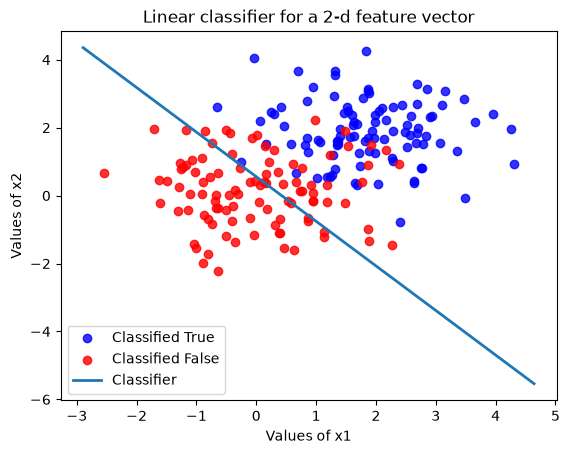

In [7]:
theta,theta_0=perceptron(X.transpose(),y,20)
plot_classifier(theta,theta_0, data)
print(f"Average hinge loss for Perceptron algorithm is {hinge_loss_full(X.transpose(),y,theta,theta_0):.4f}")
print(theta, theta_0)

✅ Даалгавар 1 — toy_perceptron загварыг хадгалж, дахин ачаалан шалгах

In [8]:
save_linear('toy_perceptron.npz', theta, theta_0, X.T, y)

toy_perceptron.npz дахин ачаалсан accuracy: 0.805 hinge: 0.6729259419999992


🔧 Засвар: доорх get_order нь seed=1-ийг дахин тогтоодог тул эпох бүрт ижил, нэг удаа хольсон дарааллыг хэрэглэнэ. Эпох бүрт өөр хольц үүсгэж байгаа гэж ойлгож болохгүй.

<div style='text-align: justify;'>
Энд буруу ангилсан олон цэг байгаа учраас өндөр алдагдалтай байна. Үүнийг хэрхэн багасгах вэ?
Энд авч үзэх ёстой нэг чухал зүйл бол шинэчлэлтүүдийг гүйцэтгэх дараалал юм. Бид зүгээр л алгоритмыг байнгын дарааллаар гүйлгэлж байна. Энэ нь сайн санаа биш юм. 

500 эерэг, 500 сөрөг жишээнээс бүрдсэн өгөгдлийн багц дээр perceptron алгоритм юу хийхийг авч үзье гэж бодвол. Эхний хэдэн эерэг жишээг (магадгүй тав) харсны дараа жишээ бүр эерэг гэдгийг шийдэж, юу ч сурахаа болино. Энэ нь хэсэг хугацаанд (дараагийн 495 жишээ) сөрөг жишээнүүдийг орж ирэх хүртэл сайн байх болно. Дараа нь бүх зүйлийг сөрөг гэж урьдчилан таамаглаж эхлэхэд хэсэг хугацаа (магадгүй арван жишээ) шаардагдана. Нэг өгөгдөл дамжуулах нэг төгсгөлд энэ нь үнэхээр цөөхөн жишээнээс л суралцах байсан (энэ тохиолдолд арван тав). 


Тиймээс, өмнөх жишээнээс сургамж авч, epoch бүрийн өмнө оролтын өгөгдлийн дарааллыг дахин холих буюу өөр өөрөөр авч үзэх хэрэгтэй. 
</div>

In [9]:
def get_order(n_samples):
    try:
        with open(str(n_samples) + '.txt') as fp:
            line = fp.readline()
            return list(map(int, line.split(',')))
    except FileNotFoundError:
        random.seed(1)
        indices = list(range(n_samples))
        random.shuffle(indices)
        return indices

In [10]:
def perceptron_stochaistic(feature_matrix, labels, T):

    update=(np.zeros(feature_matrix.shape[1]),0)
    for t in range(T):
        for i in get_order(feature_matrix.shape[0]):
            update=perceptron_single_step_update(feature_matrix[i],labels[i],update[0],update[1])
    return(update)

Одоо илүү сайн хийсэн эсэхээ харцгаая!

Average hinge loss for Perceptron algorithm is 0.3388
[2.7345 3.342 ] -5.0


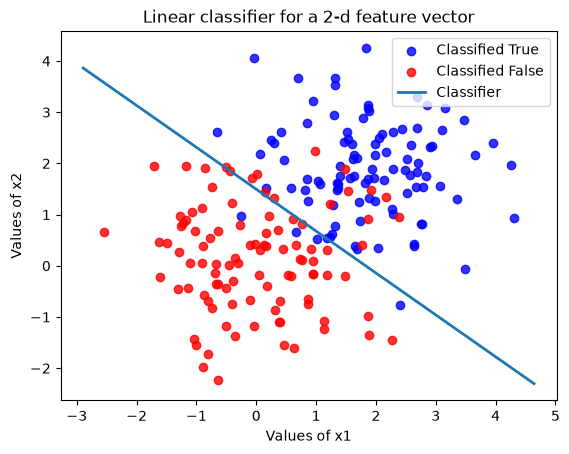

In [11]:
theta,theta_0=perceptron_stochaistic(X.transpose(),y,15)
plot_classifier(theta,theta_0, data)
print(f"Average hinge loss for Perceptron algorithm is {hinge_loss_full(X.transpose(),y,theta,theta_0):.4f}")
print(theta, theta_0)

✅ Даалгавар 1 — toy_stochastic_perceptron загварыг хадгалж, дахин ачаалан шалгах

In [12]:
save_linear('toy_stochastic_perceptron.npz', theta, theta_0, X.T, y)

toy_stochastic_perceptron.npz дахин ачаалсан accuracy: 0.91 hinge: 0.3387741017499992


🔧 Засвар: 0.3388 гэсэн урьдчилсан тоог бодит хэвлэгдсэн hinge алдагдалтай харьцуулах тайлбараар сольсон.

#### Илүү сайжирсан байна!

Бодит дундаж hinge алдагдлыг өмнөх нүдэнд хэвлэв. Хольсон дараалал нь өөр шийдэлд хүргэж болох ч бүх өгөгдөлд заавал сайжрах баталгаа байхгүй. 

### 2.2 Average Perceptron:

Одоо дундаж perceptron алгоритм руу шилжье. 

Дундаж перцептрон нь анхны perceptron алгоритмд өөрчлөлт оруулах болно. Алгоритмыг ажиллуулах үед үндсэн алгоритм нь шинэчлэгдсээр байгаа тул магадгүй зөрчилтэй чиглэлд параметрүүдийг нугалсан тул тэдгээр параметрүүдийн дундажыг эцсийн хариулт болгон авсан нь дээр. Алгоритмын шинэчлэлт бүр өмнөхтэй адил байна. Буцаасан параметрүүд θ , гэсэн хэдий ч, n алхмуудын дунджаар θ тодорхойлогдож байна: 

$$\theta_{final}=\frac{1}{n}(\theta^{(1)}+\theta^{(2)}+\theta^{(3)}+...+\theta^{(n)}) $$

✅ Даалгавар 1 — Зөв ангилсан алхмыг мөн оруулж, бүх nT алхмын жин ба bias-ийг дундажлав.

In [13]:
def avg_perceptron(feature_matrix, labels, T):
    update=(np.zeros(feature_matrix.shape[1]),0) 
    theta_sum=np.array(update[0])
    theta_0_sum=update[1]
    count=0
    for t in range(T):
        for i in get_order(feature_matrix.shape[0]):
            update=perceptron_single_step_update(feature_matrix[i],labels[i],update[0],update[1])
            theta_sum=theta_sum + update[0] # theta + theta_sum
            theta_0_sum=theta_0_sum + update[1] # theta_0 + theta_0_sum
            count=count+1
            
    avg_theta=theta_sum/count
    avg_theta_0=theta_0_sum/count
    
    return (avg_theta,avg_theta_0)

Average hinge loss for Perceptron algorithm is 0.2766
[2.270698 2.556028] -4.608


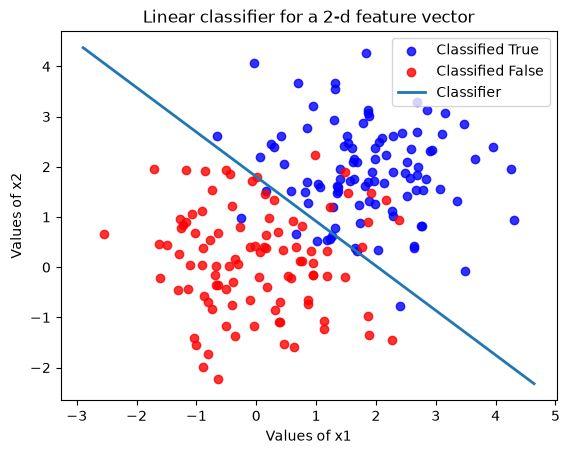

In [14]:
theta,theta_0=avg_perceptron(X.transpose(),y,5)
plot_classifier(theta,theta_0, data)
print(f"Average hinge loss for Perceptron algorithm is {hinge_loss_full(X.transpose(),y,theta,theta_0):.4f}")
print(theta, theta_0)

✅ Даалгавар 1 — toy_avg_perceptron загварыг хадгалж, дахин ачаалан шалгах

In [15]:
save_linear('toy_avg_perceptron.npz', theta, theta_0, X.T, y)

toy_avg_perceptron.npz дахин ачаалсан accuracy: 0.915 hinge: 0.27659518029700125


За тэгэхээр бид парамаметрүүдийг дунджаар гаргаснаар алдагдлыг улам багасгаж чадна. Гэхдээ бүх юм үргэлж тийм энгийн байдаггүй.

 $$ Everything\:  should  \:be\: made\: as\: simple\: as\: possible,\: but\: no\: simpler.\: -\: Albert\: Einstein$$

🔧 Засвар: тогтмолжуулагч нь λ||θ||²/2; bias-д shrinkage хийхгүй. Дараах wrapper-ийн η=1/√t нь canonical projected Pegasos биш hinge SGD хувилбар юм.

### 2.3 Pegasos Algorithm:

Pegasos алгоритм нь энгийн стохастик градиент зохистой. Энд байгаа зорилго нь зардлын үйл ажиллагааг багасгах явдал юм.
Зардлын функц нь хоёр зүйлийн нийлбэр юм. Үүнд:
- Loss function: Хажуугийн хил рүү хальтирсан цэгүүдээс болж гарсан алдагдлыг тодорхойлно.
- Regularisation: Энэ нь бат бөх загвартай байхын тулд захын хил хязгаарыг шийдвэрийн хил хязгаараас аль болох хол байлгахыг хичээдэг.


$$ J(\theta,\theta_0)\: =\: \frac{1}{n} \sum{\underbrace{loss_h (y^{(i)}(\theta.x^{(i)}+\theta_0))}_{Hinge\: loss}\: +\:\underbrace{\frac{\lambda}{2}\parallel{\theta}\:\parallel^2}_{Regularisation}}  $$

- Параметрүүдийг шинэчлэхийн тулд хуучин параметрүүд нь зардлын функцийн уламжлалын сөрөг чиглэлд хэлбэлздэг. Энэ нь дамжуулалт бүрт бид $\nabla J(\theta,\theta_0)$ хамгийн бага үнэ цэнэ рүү аваачдаг 
- Perceptron-аас ялгаатай нь SGD алхам бүрт шинэчлэлт хийнэ. Хэдийгээр алдагдал гараагүй ч гэсэн тогтмол болгох нэр томьёоны оролцооны улмаас өөрчлөлт гарна. 
- Бид бас бодит үйл ажиллагааны үнэ цэнэ ижил эсвэл бүр түүнээс ч өндөр хаа нэгтээ аваачиж болох хэт том алхмуудыг хийхгүй байхын тулд алхмын хэмжээ (эсвэл суралцах хурд) оруулах болно. 

✅ Даалгавар 1 — Pegasos-ийн margin нөхцөлийг нөхөв. Өгөгдсөн η=1/√t хуваарийг хадгалсан тул энэ нь тогтмолжуулалттай hinge SGD хувилбар; анхны Pegasos-ийн η=1/(λt), проекцтой хувилбараас ялгаатай.

In [16]:
def pegasos_single_step_update(feature_vector,label,L,eta,current_theta,current_theta_0):
    
    if(label * (np.dot(feature_vector, current_theta) + current_theta_0)<=1): # loss_h
        current_theta=current_theta*(1-eta*L)+eta*np.dot(label,feature_vector)
        current_theta_0=current_theta_0+eta*label
    else:
        current_theta=current_theta*(1-eta*L)
    
    return (current_theta,current_theta_0)


def pegasos(feature_matrix, labels, T, L):

    update=(np.zeros(feature_matrix.shape[1]),0) #why not just theta and theta zero
    count=0
    for t in range(T):
        
        for i in get_order(feature_matrix.shape[0]):
            count=count+1
            eta=1/np.sqrt(count)
            
            update=pegasos_single_step_update(feature_matrix[i],labels[i],L,eta,update[0],update[1])        
    return update

Average hinge loss for Pegasos algorithm is 0.2509


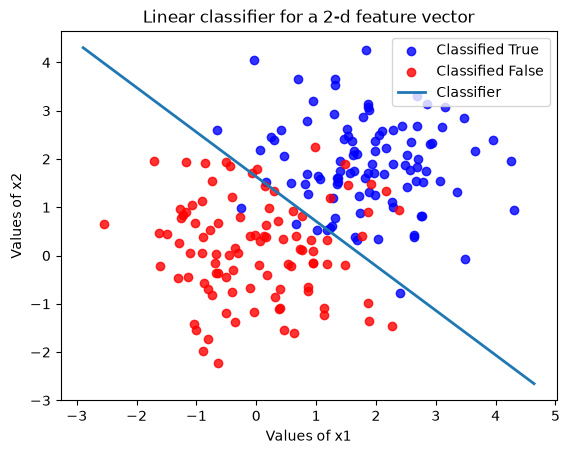

In [17]:
theta,theta_0=pegasos(X.transpose(),y,T=15,L=0.1)
plot_classifier(theta,theta_0, data)
print(f"Average hinge loss for Pegasos algorithm is {hinge_loss_full(X.transpose(),y,theta,theta_0):.4f}")

✅ Даалгавар 1 — toy_pegasos загварыг хадгалж, дахин ачаалан шалгах

In [18]:
save_linear('toy_pegasos.npz', theta, theta_0, X.T, y)

toy_pegasos.npz дахин ачаалсан accuracy: 0.92 hinge: 0.25093277797345964


### Linear classifier Даалгавар

titanic санг ашиглан сургалт хийн үр дүнг дүгнэж бичнэ үү

✅ Даалгавар 2 — Titanic дээр perceptron, дундаж perceptron ба Pegasos

Survived нь зорилтот хувьсагч. Нас, тийзний үнэ, гэр бүлийн тоо, хүйс, буудал, тасалбарын ангийг ашиглав. `alive` зэрэг хариуг задруулах шинжийг ашиглаагүй. Импутаци, хэмжээс ба кодчиллыг зөвхөн сургалтын 80%-д тааруулна.

In [19]:
from urllib.request import urlretrieve
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
Path('data').mkdir(exist_ok=True)
titanic_path = Path('data/titanic.csv')
if not titanic_path.exists():
    urlretrieve('https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv', titanic_path)
titanic = pd.read_csv(titanic_path)
num_cols = ['age', 'fare', 'sibsp', 'parch']
cat_cols = ['sex', 'embarked', 'pclass']
tit_train, tit_test = train_test_split(titanic, test_size=0.2, random_state=42, stratify=titanic.survived)
preprocess = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num_cols),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore', sparse_output=False)), cat_cols)
])
tit_X_train = preprocess.fit_transform(tit_train[num_cols + cat_cols])
tit_X_test = preprocess.transform(tit_test[num_cols + cat_cols])
tit_y_train = tit_train.survived.to_numpy()
tit_y_test = tit_test.survived.to_numpy()
tit_pm_train = 2 * tit_y_train - 1
tit_pm_test = 2 * tit_y_test - 1
linear_titanic = {}
tit_rows = []
for name, trainer in [('perceptron', perceptron_stochaistic), ('avg_perceptron', avg_perceptron), ('pegasos', lambda A, b, T: pegasos(A, b, T, L=0.01))]:
    tw, tb = trainer(tit_X_train, tit_pm_train, 30)
    prediction = np.where(tit_X_test @ tw + tb > 0, 1, -1)
    linear_titanic[name] = (tw, tb)
    tit_rows.append({'model': name, 'test_accuracy': accuracy_score(tit_pm_test, prediction)})
    save_linear(f'titanic_{name}.npz', tw, tb, tit_X_test, tit_pm_test)
titanic_linear_results = pd.DataFrame(tit_rows)
display(titanic_linear_results)
best_tit = titanic_linear_results.iloc[titanic_linear_results.test_accuracy.argmax()]
display(Markdown(f'Ижил {len(tit_test)} тестийн зорчигч дээр хамгийн өндөр accuracy **{best_tit["model"]}: {best_tit.test_accuracy:.3f}**. Дундажлах нь алхам бүрийн хэлбэлзлийг бууруулдаг, тогтмолжуулалт нь жинг хязгаарладаг. Гэхдээ энэ нэг хуваалтын үр дүнгээр алгоритмуудыг нийтэд нь эрэмбэлэхгүй.'))

titanic_perceptron.npz дахин ачаалсан accuracy: 0.7150837988826816 hinge: 1.7719716936432977


titanic_avg_perceptron.npz дахин ачаалсан accuracy: 0.8212290502793296 hinge: 0.8196236553574182


titanic_pegasos.npz дахин ачаалсан accuracy: 0.776536312849162 hinge: 0.4570736999313868


,model,test_accuracy
0,perceptron,0.715084
1,avg_perceptron,0.821229
2,pegasos,0.776536


Ижил 179 тестийн зорчигч дээр хамгийн өндөр accuracy **avg_perceptron: 0.821**. Дундажлах нь алхам бүрийн хэлбэлзлийг бууруулдаг, тогтмолжуулалт нь жинг хязгаарладаг. Гэхдээ энэ нэг хуваалтын үр дүнгээр алгоритмуудыг нийтэд нь эрэмбэлэхгүй.

# 3. Logistic regression

Энд логистик регресс хэрхэн ажилладаг талаар тайлбарлаж, энгийн Numpy дээр хэрэгжүүлнэ.
Логистик регресс нь хяналттай сургалтын ангиллын алгоритм бөгөөд энэ нь ангиллыг тооцоолох боломжтой гэсэн үг юм.
label-тэй ажиглалт дээр үндэслэсэн шинэ ажиглалт хийж шалгах дасгал ажил.

## Өгөгдлийн сан үүсгэх

🔧 Засвар: доорх make_classification нь 100 биш 200 ажиглалт үүсгэдэг.

Зөвхөн 200 ажиглалт, 2 онцлог бүхий хоёртын ангиллын бодлогод логистик регрессийг хэрэглэе.

In [20]:
X, y = make_classification(
        n_samples=200, 
        n_features=2,
        n_redundant=0,
        n_informative=2,
        random_state=0, 
        n_clusters_per_class=2)
print(X.shape, y.shape)
# X=X.transpose()

(200, 2) (200,)


Text(0, 0.5, '$X_2$')

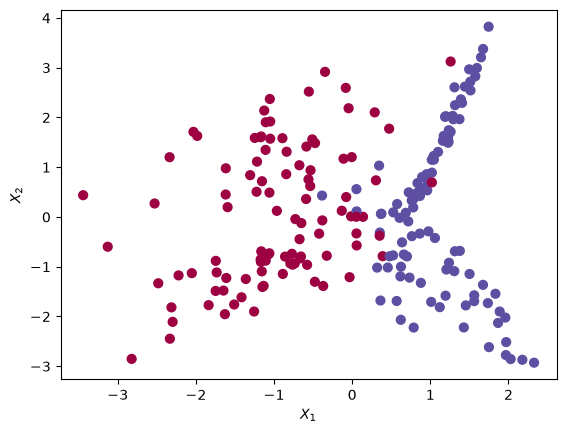

In [21]:
plt.scatter(X[:, 0], X[:, 1], c=y.ravel(), s=40, cmap=plt.cm.Spectral)
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
# blue dots = 1, red dots = 0

🔧 Засвар: доорх make_classification нь 100 биш 200 ажиглалт үүсгэдэг.

Бидэнд $X$ 2 feature-тэй $\theta$ гэсэн 200 ажиглалт байгаа бөгөөд тэдгээрийн $y$ label-ийг бид мэднэ. Бид шинэ ажиглалтын label-ийг таамаглах боломжтой юу?

## 3. Logistic regression

Логистик регресс нь ажиглалт тодорхой ангилалд хамаарах магадлалыг загварчилдаг.
Эдгээр магадлалыг үүсгэхийн тулд логистик регресс нь **sigmoid** функцийг ашигладаг. Энэ функц нь бодит тоог 0-ээс 1-ийн хоорондох утгуудад буулгадаг.

\begin{equation} 
g(z) = \frac{1}{1+e^{-z}}
\end{equation}

Дараах байдлаар таамаглалыг тодорхойлж болно $h(X) = g(X \theta)$
энд 
- $\theta$ коэффициэнт вектор.
- $X$ нь бүх ажиглалтын вектор юм.

$h(X)$ бидэнд 1 хүртэлх таамаглал өгнө,
- хэрэв $ X \theta \geqslant 0 $, бол $h(X) \geqslant 0.5$, таамаглал $y = 1$
- хэрэв $ X \theta < 0 $, бол $h(X) < 0.5$, таамаглал $y = 0$

✅ Даалгавар 3 — Тоон тогтвортой sigmoid ба h(X)=σ(Xθ)-г нөхөв. exp-ийн оролтыг хязгаарлаж overflow-оос сэргийлэв.

In [22]:
def add_intercept(X):
    intercept = np.ones((X.shape[0], 1))
    return np.concatenate((intercept, X), axis=1)

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500))) # томъёо 1

def calc_h(X, theta):
    z = X @ theta
    h = sigmoid(z)
    return h

XX = add_intercept(X)
theta = np.zeros(XX.shape[1])
h = calc_h(XX, theta)

print(XX)
print(theta)
print(h)

[[ 1.00000000e+00  6.17010831e-01 -1.19399527e+00]
 [ 1.00000000e+00  5.74173999e-02 -5.72398146e-01]
 [ 1.00000000e+00 -5.58915168e-01  7.55356227e-01]
 [ 1.00000000e+00  3.68073023e-01  6.15571203e-02]
 [ 1.00000000e+00  2.32747048e+00 -2.92856890e+00]
 [ 1.00000000e+00 -1.36575239e-02  1.33941322e-02]
 [ 1.00000000e+00  9.76010042e-01 -2.88595509e-01]
 [ 1.00000000e+00  1.16015480e+00  1.53217800e+00]
 [ 1.00000000e+00 -1.10808024e+00  1.34874056e+00]
 [ 1.00000000e+00 -4.23038156e-01 -3.35160744e-01]
 [ 1.00000000e+00  7.17691503e-01 -8.84913923e-02]
 [ 1.00000000e+00  1.01966758e+00  8.91208862e-01]
 [ 1.00000000e+00  7.61860774e-01  3.32491195e-01]
 [ 1.00000000e+00  1.31601904e+00  2.24730790e+00]
 [ 1.00000000e+00 -1.83659331e+00 -1.77175130e+00]
 [ 1.00000000e+00 -2.33251139e+00 -2.44662001e+00]
 [ 1.00000000e+00  1.29460011e+00  1.96406525e+00]
 [ 1.00000000e+00  5.69506693e-01 -1.68811299e+00]
 [ 1.00000000e+00  1.96705457e+00 -2.77545112e+00]
 [ 1.00000000e+00  1.23891237e+

# Loss function

loss функцийг дараах байдалтай тодорхойлно,
\begin{equation} 
J(\theta) = \frac{1}{m}(-y \log(h) - (1 - y) \log(1 - h))
\end{equation}
энд $m$ жишээний тоо.

алдааг буруу ангилсан тохиолдлын жишээ,
- хэрэв $y=0$ болон $h\rightarrow 1$, тэгвэл $J(\theta)\rightarrow ∞$  (хүчтэй алдаа)
- хэрэв $y=0$ болон $h\rightarrow 0$, тэгвэл $J(\theta)\rightarrow 0$  (бага алдаа)
- хэрэв $y=1$ болон $h\rightarrow 0$, тэгвэл $J(\theta)\rightarrow ∞$  (хүчтэй алдаа)
- хэрэв $y=1$ болон $h\rightarrow 1$, тэгвэл $J(\theta)\rightarrow 0$  (бага алдаа)

✅ Даалгавар 3 — Бүх дээжийн дундаж binary log-loss-ыг бодов; log(0)-оос сэргийлнэ.

In [23]:
#алдааг тодорхойлох
cost = -np.mean(y * np.log(np.clip(h, 1e-15, 1-1e-15)) + (1-y) * np.log1p(-np.clip(h, 1e-15, 1-1e-15)))
print(cost)

0.6931471805599452


## Gradiend descent

Таамаглалыг сайжруулахын тулд, бид алдааны $J(\theta)$ утгыг багасгах шаардлагатай. Үүнийг $\theta$ утгыг тохируулах замаар гүйцэтгэнэ. Энэ нь алдааны функцээс уламжлал авч $\theta$ бүрийг тохируулснаар хийгдэнэ. Градиент нь хэр их алдаа хэр хэмжээгээр коэффициэнтийг өөрлөхийг илэрхийлнэ. Энэ аргыг *Gradient Descent* гэдэг.
\begin{equation} 
\theta_j := \theta_j - \alpha \frac{\partial J(\theta)}{\partial \theta_j}
\end{equation}
энд $\alpha$ бол сурах хурд.

Ингэснээр бид
\begin{equation} 
\frac{\partial J(\theta)}{\partial \theta_j} = \frac{1}{m} X^T (h - y) 
\end{equation}

✅ Даалгавар 3 — ∇J = Xᵀ(h−y)/m, θ ← θ−α∇J.

In [24]:
m = y.size
alpha = 0.01

gradient = XX.T @ (h-y) / m # томъёо 2
theta -= alpha * gradient # томъёо 1

print(gradient)
print(theta)

[ 0.         -0.51369123 -0.00744698]
[0.00000000e+00 5.13691229e-03 7.44697744e-05]


## Training the model

Бид дээрх алхамыг коэффициент тохиртол давтан хийх хэрэгтэй.

✅ Даалгавар 3 — 50000 алхмын gradient descent, алдагдлын түүхийг хадгална.

In [25]:
num_iter = 50000
cost_list = []

for i in range(num_iter):
    h = calc_h(XX, theta)
    cost = -np.mean(y * np.log(np.clip(h, 1e-15, 1-1e-15)) + (1-y) * np.log1p(-np.clip(h, 1e-15, 1-1e-15)))
    cost_list.append(cost)
    
    gradient = XX.T @ (h-y) / m
    theta -= alpha * gradient


    if i % 10000 == 0:
        print('Cost: {}'.format(cost))

print('Adjusted coefficient: {}'.format(theta))

Cost: 0.6905129414329346


Cost: 0.1376274679857761


Cost: 0.1323598899646972


Cost: 0.13119759138873913


Cost: 0.13084909560333202


Adjusted coefficient: [-1.24551419  5.30677291 -1.00889134]


## Plot the loss function

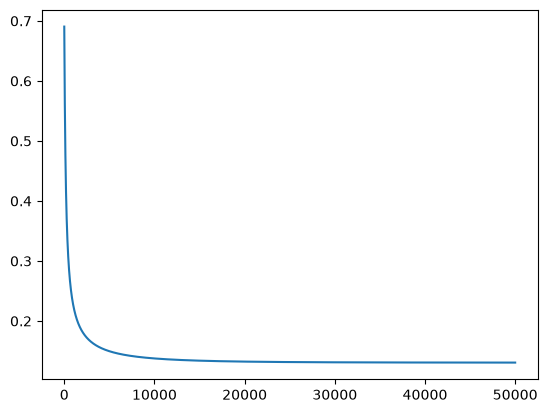

In [26]:
plt.plot(range(num_iter), cost_list)

Алдааны утга багасах нь сургалт амжилттай явагдаж буйн илрэл юм.

## Таамаглалуудыг дэвшүүлэх

Бид таамаглалын магадлалуудыг sigmoid функц авч гаргана.

In [27]:
preds_prob = calc_h(XX, theta)
print(preds_prob)

[9.62073241e-01 4.10154782e-01 6.87051206e-03 6.56032085e-01
 9.99999217e-01 2.08910564e-01 9.85587059e-01 9.66604323e-01
 2.06175409e-04 4.09991414e-02 9.34158134e-01 9.63261412e-01
 9.21438946e-01 9.69851579e-01 1.00586363e-04 1.42998285e-05
 9.74496524e-01 9.70109002e-01 9.99993815e-01 9.98087409e-01
 5.62651280e-04 1.44464379e-03 5.10422714e-04 8.80999268e-03
 4.49923208e-01 1.02177394e-02 9.99821128e-01 1.19367784e-03
 1.36120055e-03 3.07015239e-03 2.78754041e-03 8.34473784e-01
 6.69719076e-03 9.91844755e-01 1.49477430e-06 3.39018384e-05
 1.46352640e-04 9.82570940e-01 1.40107806e-01 3.49689593e-01
 9.80149308e-01 1.96064965e-03 3.95686737e-03 9.07914158e-01
 1.20167301e-03 3.24713147e-08 5.12934570e-03 1.79171610e-01
 2.60900427e-04 9.94371274e-01 9.36613675e-01 1.11361292e-01
 9.97102834e-01 1.21312585e-04 7.66238814e-02 9.63442123e-01
 8.48519932e-05 2.84035465e-03 1.01047886e-01 9.75479308e-01
 1.12990335e-04 9.36615642e-01 7.82816635e-02 7.20721829e-01
 1.22443683e-05 9.343505

🔧 Засвар: NumPy round нь яг 0.5 дээр тэгш бүхэлд ойртуулж 0 буцаана; энэ нь >=0.5 босгын дүрмээс зөвхөн тэнцүү тохиолдолд ялгаатай.

Өмнө нь үзсэнчлэн sigmoid функцийн шийдвэрийн хязгаарыг бид 0.5 гэж авсан ба үүнийг round функц ашиглан тэгшитгэж болно.

In [28]:
preds = preds_prob.round()
print(preds)

[1. 0. 0. 1. 1. 0. 1. 1. 0. 0. 1. 1. 1. 1. 0. 0. 1. 1. 1. 1. 0. 0. 0. 0.
 0. 0. 1. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 1. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0.
 0. 1. 1. 0. 1. 0. 0. 1. 0. 0. 0. 1. 0. 1. 0. 1. 0. 1. 0. 1. 1. 0. 1. 0.
 0. 1. 0. 0. 1. 1. 0. 1. 0. 0. 0. 1. 0. 1. 1. 0. 1. 0. 1. 0. 0. 1. 1. 0.
 1. 1. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 1. 1. 1. 0. 0. 1. 1. 0. 1. 1. 1. 1.
 0. 0. 0. 1. 1. 0. 0. 1. 1. 0. 1. 0. 0. 1. 1. 0. 0. 0. 1. 1. 0. 1. 1. 0.
 0. 1. 1. 0. 1. 0. 0. 1. 1. 1. 1. 1. 0. 0. 1. 0. 0. 0. 0. 1. 1. 0. 1. 0.
 0. 1. 1. 1. 0. 1. 0. 0. 1. 1. 1. 1. 1. 0. 0. 1. 0. 1. 0. 1. 1. 0. 1. 1.
 1. 1. 1. 1. 1. 0. 1. 0.]


Эцэст нь бид сургалтын үр дүнг гаргах боломжтой боллоо.

In [29]:
score_numpy = (preds == y).mean()
print('Score Numpy: {}'.format(score_numpy))

Score Numpy: 0.96


Сургасан өгөгдөлд өндөр үр дүн үзүүлж байгаа боловч бид сургалтанд ашиглагдаагүй өгөгдлөөр туршиж үзэж болно.

🔧 Засвар: new_x-ийн intercept-ийг тайлбартай нь нийцүүлж 0-ээс 1 болгов.

In [30]:
new_x = np.array([1, -0.8, 0.8])   # new observation (-0.8, 0.8)  with an intercept of 1
print(new_x)
preds_prob_new_x = calc_h(new_x, theta).round()
print("шинэ өгөгдлийн таамагласан утга: ", preds_prob_new_x)

[ 1.  -0.8  0.8]
шинэ өгөгдлийн таамагласан утга:  0.0


## Шийдвэрийн хязгаарыг дүрсэлж харвал

🔧 Засвар: шинэ дээжийн ангиллыг урьдчилан зөв гэж батлаагүй; түүний таамаглалыг өмнөх нүдний бодит үр дүнгээр уншина.

[[6.43832548e-08 1.20268685e-07 2.24663322e-07 ... 9.99997269e-01
  9.99998538e-01 9.99999217e-01]
 [5.60255490e-08 1.04656392e-07 1.95499377e-07 ... 9.99996861e-01
  9.99998320e-01 9.99999100e-01]
 [4.87527719e-08 9.10707586e-08 1.70121255e-07 ... 9.99996393e-01
  9.99998069e-01 9.99998966e-01]
 ...
 [9.34529146e-11 1.74571165e-10 3.26101029e-10 ... 9.98121779e-01
  9.98993657e-01 9.99461024e-01]
 [8.13216235e-11 1.51909768e-10 2.83769267e-10 ... 9.97842197e-01
  9.98843707e-01 9.99380671e-01]
 [7.07651171e-11 1.32190087e-10 2.46932667e-10 ... 9.97521101e-01
  9.98671444e-01 9.99288347e-01]]


(-2.9285689040924416, 3.8246288578434964)

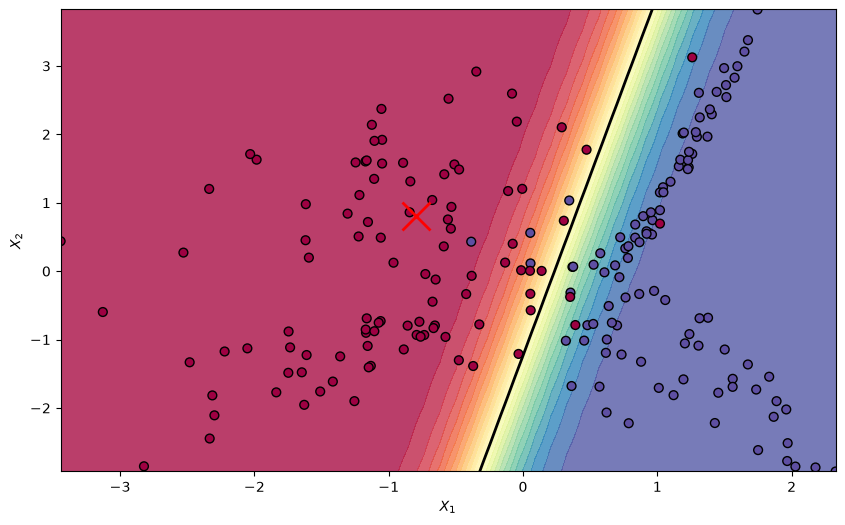

In [31]:
plt.figure(figsize=(10, 6))

x1_min, x1_max = X[:,0].min(), X[:,0].max(),
x2_min, x2_max = X[:,1].min(), X[:,1].max(),
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max), np.linspace(x2_min, x2_max))
grid = np.c_[xx1.ravel(), xx2.ravel()]

grid = add_intercept(grid)
probs = calc_h(grid, theta)
probs = probs.reshape(xx1.shape)
print(probs)
ax = plt.gca()
plt.contourf(xx1, xx2, probs, levels=25, cmap=plt.cm.Spectral, alpha=0.8)
plt.contour(xx1, xx2, probs, [0.5], linewidths=2, colors='black') # decision boundary at 0.5
plt.scatter(X[:, 0], X[:, 1], c=y.ravel(), s=40, cmap=plt.cm.Spectral, edgecolors='black')
plt.plot(-0.8, 0.8, 'rx', markersize=20, markeredgewidth=2)  # new observation

plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
ax.set_xlim([x1_min, x1_max])
ax.set_ylim([x2_min, x2_max])

## Sklearn хэрэгжүүлэлт

Мэдээж logistic regression нь аль хэдийн Scikit-learn хөгжүүлэгдсэн байгаа.

In [32]:
model = LogisticRegression(C=1e20, solver='lbfgs')
model.fit(X, y)
preds = model.predict(X)

score_sklearn = (preds == y).mean()
print('Score Sklearn: {}'.format(score_sklearn))
print(model.intercept_, model.coef_)

Score Sklearn: 0.96
[-1.30275199] [[ 5.45559158 -1.05149194]]


✅ Даалгавар 3 — Хиймэл өгөгдлийн NumPy/sklearn харьцуулалт, тоон градиент ба загваруудыг дахин ачаалах

In [33]:
assert abs(score_numpy - score_sklearn) < 0.02
print('50000 GD алхам ба sklearn-ийн коэффициэнтийн зөрүү:', np.linalg.norm(theta-np.r_[model.intercept_,model.coef_[0]]))
assert abs(log_loss(y, calc_h(XX,theta)) - log_loss(y,model.predict_proba(X)[:,1])) < 1e-3
assert np.mean(np.abs(calc_h(XX,theta)-model.predict_proba(X)[:,1])) < 0.01
probe = np.array([0.1, -0.2, 0.3])
def objective(t):
    z = XX @ t
    return np.mean(np.logaddexp(0, z) - y*z)
analytic = XX.T @ (sigmoid(XX @ probe)-y) / len(y)
eps = 1e-6
numeric = np.array([(objective(probe + np.eye(len(probe))[j]*eps) - objective(probe - np.eye(len(probe))[j]*eps))/(2*eps) for j in range(len(probe))])
np.testing.assert_allclose(analytic, numeric, atol=1e-7)
print('Тоон градиентын хамгийн их алдаа:', np.max(np.abs(analytic-numeric)))
for filename, weights, expected in [('numpy_logreg_theta.npy', theta, preds_prob >= 0.5), ('sklearn_logreg_theta.npy', np.r_[model.intercept_, model.coef_[0]], model.predict(X))]:
    np.save(filename, weights)
    loaded = np.load(filename, allow_pickle=False)
    assert np.array_equal((XX @ loaded >= 0).astype(int), expected.astype(int))
    print(filename, 'дахин ачаалсан accuracy:', accuracy_score(y, XX @ loaded >= 0))
    saved_model_files.append(filename)
display(Markdown(f'NumPy accuracy **{score_numpy:.3f}**, sklearn **{score_sklearn:.3f}**; градиентыг төвийн ялгавраар шалгав. 50000 тогтмол алхмын GD бүрэн нийлээгүй тул коэффициент яг ижил биш; log-loss ба магадлалыг мөн харьцуулав. Энэ нь сургалтын үнэлгээ; дараагийн Titanic туршилт нь тусдаа тестийн өгөгдөл ашиглана.'))

50000 GD алхам ба sklearn-ийн коэффициэнтийн зөрүү: 0.16503930313004778
Тоон градиентын хамгийн их алдаа: 1.1183475326359549e-10
numpy_logreg_theta.npy дахин ачаалсан accuracy: 0.96
sklearn_logreg_theta.npy дахин ачаалсан accuracy: 0.96


NumPy accuracy **0.960**, sklearn **0.960**; градиентыг төвийн ялгавраар шалгав. 50000 тогтмол алхмын GD бүрэн нийлээгүй тул коэффициент яг ижил биш; log-loss ба магадлалыг мөн харьцуулав. Энэ нь сургалтын үнэлгээ; дараагийн Titanic туршилт нь тусдаа тестийн өгөгдөл ашиглана.

### Logistic regression Даалгавар

titanic санг ашиглан сургалт хийн үр дүнг дүгнэж бичнэ үү

✅ Даалгавар 3 — Titanic логистик регресс, NumPy ба sklearn

Дээр бэлтгэсэн ижил сургалт/тестийг ашиглана. Тааруулах явцад тестийн шошгыг ашиглахгүй.

Titanic NumPy accuracy: 0.8044692737430168 log-loss: 0.46307029519928716
Titanic sklearn accuracy: 0.8044692737430168


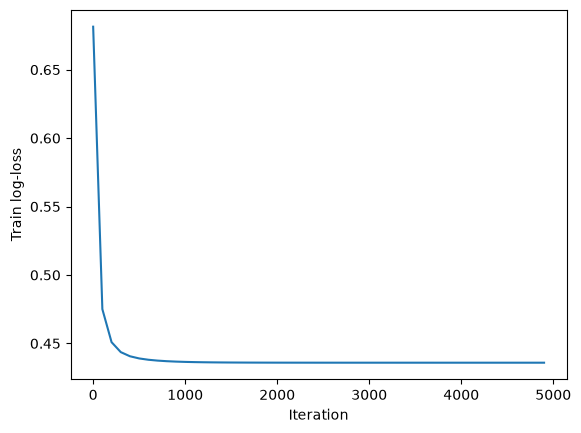

titanic_logreg.npz дахин ачаалсан accuracy: 0.8044692737430168
titanic_sklearn_logreg.npz дахин ачаалсан accuracy: 0.8044692737430168


Titanic тест дээр NumPy **0.804**, sklearn **0.804** accuracy үзүүлэв. Дундаж log-loss **0.463**. Шугаман ангилагчийн харьцуулалтад ижил хуваалт/боловсруулалт хэрэглэсэн тул үр дүнг харьцуулж болно; амьд үлдэх бүх нөлөөг шугаман загвар илэрхийлэхгүй.

In [34]:
tit_XX_train = add_intercept(tit_X_train)
tit_XX_test = add_intercept(tit_X_test)
tit_theta = np.zeros(tit_XX_train.shape[1])
tit_costs = []
for step in range(5000):
    h_tit = sigmoid(tit_XX_train @ tit_theta)
    tit_theta -= 0.1 * tit_XX_train.T @ (h_tit-tit_y_train) / len(tit_y_train)
    if step % 100 == 0:
        z = tit_XX_train @ tit_theta
        tit_costs.append(np.mean(np.logaddexp(0, z)-tit_y_train*z))
tit_ref = LogisticRegression(C=1e10, max_iter=2000, tol=1e-10).fit(tit_X_train, tit_y_train)
tit_prob = sigmoid(tit_XX_test @ tit_theta)
tit_acc = accuracy_score(tit_y_test, tit_prob >= 0.5)
tit_acc_ref = tit_ref.score(tit_X_test, tit_y_test)
print('Titanic NumPy accuracy:', tit_acc, 'log-loss:', log_loss(tit_y_test, tit_prob))
print('Titanic sklearn accuracy:', tit_acc_ref)
assert np.mean((tit_prob >= 0.5) == tit_ref.predict(tit_X_test)) >= 0.98
plt.plot(np.arange(len(tit_costs))*100, tit_costs)
plt.xlabel('Iteration'); plt.ylabel('Train log-loss'); plt.show()
for filename, weights, expected in [('titanic_logreg.npz', tit_theta, tit_prob >= 0.5), ('titanic_sklearn_logreg.npz', np.r_[tit_ref.intercept_, tit_ref.coef_[0]], tit_ref.predict(tit_X_test))]:
    np.savez(filename, theta=weights, threshold=0.5)
    with np.load(filename, allow_pickle=False) as z:
        restored = sigmoid(tit_XX_test @ z['theta']) >= float(z['threshold'])
        assert np.array_equal(restored, expected)
        print(filename, 'дахин ачаалсан accuracy:', accuracy_score(tit_y_test, restored))
    saved_model_files.append(filename)
# Урьдчилсан боловсруулалтын параметрүүдийг мөн тусад нь хадгална.
num_imp, scale = preprocess.named_transformers_['num'].steps[0][1], preprocess.named_transformers_['num'].steps[1][1]
cat_imp, enc = preprocess.named_transformers_['cat'].steps[0][1], preprocess.named_transformers_['cat'].steps[1][1]
prep_values = dict(num_cols=np.array(num_cols), cat_cols=np.array(cat_cols), medians=num_imp.statistics_, mean=scale.mean_, scale=scale.scale_, modes=cat_imp.statistics_.astype(str))
for j, cats in enumerate(enc.categories_): prep_values[f'categories_{j}'] = cats.astype(str)
np.savez('titanic_preprocessing.npz', **prep_values)
with np.load('titanic_preprocessing.npz', allow_pickle=False) as z:
    raw_num = tit_test[list(z['num_cols'])].to_numpy(dtype=float)
    raw_num = np.where(np.isnan(raw_num), z['medians'], raw_num)
    numeric_loaded = (raw_num-z['mean'])/z['scale']
    blocks = [numeric_loaded]
    for j, col in enumerate(z['cat_cols']):
        vals = tit_test[col].fillna(z['modes'][j]).astype(str).to_numpy()
        blocks.append((vals[:, None] == z[f'categories_{j}'][None, :]).astype(float))
    tit_rebuilt = np.column_stack(blocks)
np.testing.assert_allclose(tit_rebuilt, tit_X_test)
assert accuracy_score(tit_y_test, sigmoid(add_intercept(tit_rebuilt) @ tit_theta) >= 0.5) == tit_acc
saved_model_files.append('titanic_preprocessing.npz')
display(Markdown(f'Titanic тест дээр NumPy **{tit_acc:.3f}**, sklearn **{tit_acc_ref:.3f}** accuracy үзүүлэв. Дундаж log-loss **{log_loss(tit_y_test, tit_prob):.3f}**. Шугаман ангилагчийн харьцуулалтад ижил хуваалт/боловсруулалт хэрэглэсэн тул үр дүнг харьцуулж болно; амьд үлдэх бүх нөлөөг шугаман загвар илэрхийлэхгүй.'))

# 4. PCA Бууруулах арга
Үндсэн бүрэлдэхүүн хэсгийн анализ буюу PCA нь том хэмжээний мэдээллийн хүснэгт дэх мэдээллийн агуулгыг илүү хялбараар харж, задлан шинжилж болох жижиг багц "хураангуй индекс"-ээр нэгтгэн дүгнэх боломжийг олгодог статистикийн горим юм.

In [35]:
from sklearn import datasets
from sklearn.decomposition import PCA

iris = datasets.load_iris()

In [36]:
iris.get("feature_names")

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

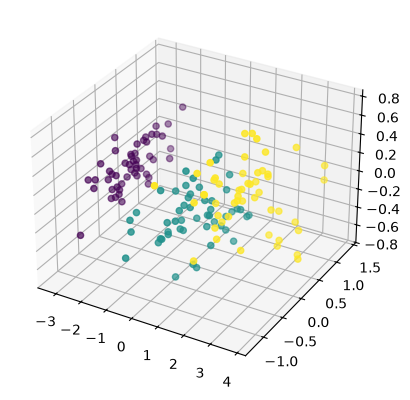

In [37]:
pca = PCA(n_components=3)
pca.fit(iris.data)
X = pca.transform(iris.data)
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=iris.target)

✅ Даалгавар 4 — Iris PCA жинг хадгалж, проекц ба дисперсийн хувийг давтан шалгах

In [38]:
np.savez('iris_pca.npz', mean=pca.mean_, components=pca.components_, explained_variance_ratio=pca.explained_variance_ratio_)
with np.load('iris_pca.npz', allow_pickle=False) as z:
    restored_iris = (iris.data-z['mean']) @ z['components'].T
    np.testing.assert_allclose(restored_iris, X, atol=1e-12)
    restored_ratio = np.var(restored_iris, axis=0, ddof=1)/np.var(iris.data, axis=0, ddof=1).sum()
    np.testing.assert_allclose(restored_ratio, z['explained_variance_ratio'], atol=1e-12)
print('Iris PCA дахин ачаалсан дисперсийн хувь:', restored_ratio)
saved_model_files.append('iris_pca.npz')

Iris PCA дахин ачаалсан дисперсийн хувь: [0.92461872 0.05306648 0.01710261]


### PCA Даалгавар

mnist санг дээрх аргаар бууруулан дүрсэлж харуулна уу

✅ Даалгавар 4 — MNIST PCA 2D ба 3D

MNIST сургалтын сангаас ангиллын харьцааг хадгалсан 10000 зураг сонгож [0,1] хэмжээс дээр төвлөрүүлэн 3 үндсэн бүрэлдэхүүн тооцов. Тестийн санг PCA сургахад ашиглаагүй.

0.3%

0.7%

1.0%

1.3%

1.7%

2.0%

... (347 outputs left out)

99.4%

100.0%

100.0%

Тайлбарласан дисперсийн хувь: [0.0982284  0.06956903 0.06051037]
Нийлбэр: 0.22830780491193364


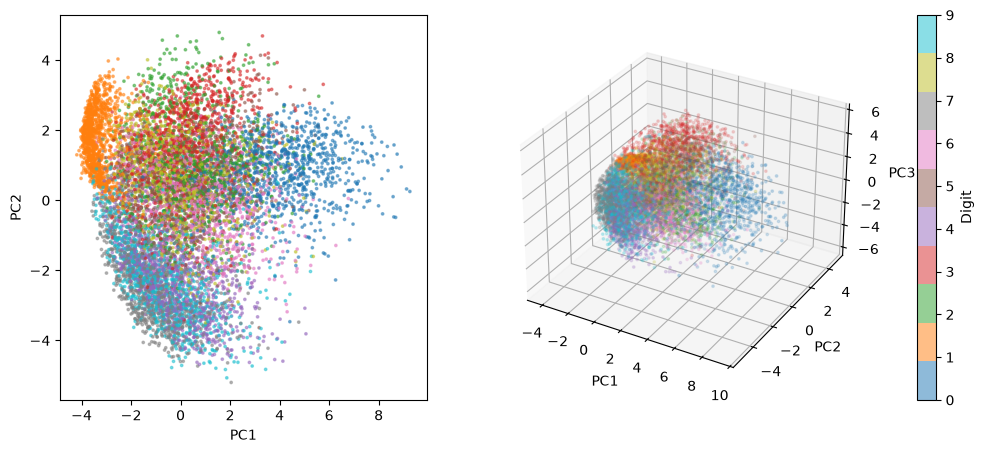

Эхний хоёр бүрэлдэхүүн нийт дисперсийн **16.78%**, эхний гурав **22.83%**-ийг хадгалав. Өнгөөр ялгасан цифрүүд хэсэгчлэн бөөгнөрөх ч давхцал их байна. PCA нь шошго ашигладаггүй учраас ангийг хамгийн сайн тусгаарлах зорилготой биш; 2–3 хэмжээс нь бүх мэдээллийг хадгалахгүй. Дахин ачаалсан проекц ба дисперсийн хувь таарсан.

In [39]:
from torchvision.datasets import MNIST
mnist_train = MNIST(root='./data', train=True, download=True)
mnist_ids, _ = train_test_split(np.arange(len(mnist_train)), train_size=10000, random_state=42, stratify=mnist_train.targets.numpy())
mnist_X = mnist_train.data[mnist_ids].numpy().reshape(-1, 784).astype(np.float64) / 255
mnist_y = mnist_train.targets[mnist_ids].numpy()
mnist_pca = PCA(n_components=3, svd_solver='randomized', random_state=42, iterated_power=7)
mnist_projection = mnist_pca.fit_transform(mnist_X)
print('Тайлбарласан дисперсийн хувь:', mnist_pca.explained_variance_ratio_)
print('Нийлбэр:', mnist_pca.explained_variance_ratio_.sum())
fig = plt.figure(figsize=(13, 5))
a2 = fig.add_subplot(121)
a2.scatter(mnist_projection[:, 0], mnist_projection[:, 1], c=mnist_y, cmap='tab10', s=3, alpha=0.5)
a2.set_xlabel('PC1'); a2.set_ylabel('PC2')
a3 = fig.add_subplot(122, projection='3d')
img = a3.scatter(*mnist_projection.T, c=mnist_y, cmap='tab10', s=3, alpha=0.5)
a3.set_xlabel('PC1'); a3.set_ylabel('PC2'); a3.set_zlabel('PC3')
fig.colorbar(img, ax=[a2,a3], ticks=range(10), label='Digit')
plt.show()
# sklearn transform-оос тусдаа матриц үржүүлэлт ба covariance шалгалт.
manual_projection = (mnist_X-mnist_pca.mean_) @ mnist_pca.components_.T
np.testing.assert_allclose(manual_projection, mnist_pca.transform(mnist_X), atol=1e-10)
np.testing.assert_allclose(mnist_pca.components_ @ mnist_pca.components_.T, np.eye(3), atol=1e-10)
empirical_ratio = np.var(manual_projection, axis=0, ddof=1) / np.var(mnist_X, axis=0, ddof=1).sum()
np.testing.assert_allclose(empirical_ratio, mnist_pca.explained_variance_ratio_, atol=1e-6)
np.savez('mnist_pca.npz', mean=mnist_pca.mean_, components=mnist_pca.components_, explained_variance=mnist_pca.explained_variance_, explained_variance_ratio=mnist_pca.explained_variance_ratio_, singular_values=mnist_pca.singular_values_, n_samples=mnist_pca.n_samples_)
with np.load('mnist_pca.npz', allow_pickle=False) as z:
    restored_projection = (mnist_X-z['mean']) @ z['components'].T
    np.testing.assert_allclose(restored_projection, manual_projection, atol=1e-10)
    np.testing.assert_allclose(np.var(restored_projection, axis=0, ddof=1) / np.var(mnist_X, axis=0, ddof=1).sum(), z['explained_variance_ratio'], atol=1e-6)
saved_model_files.append('mnist_pca.npz')
display(Markdown(f'Эхний хоёр бүрэлдэхүүн нийт дисперсийн **{100*mnist_pca.explained_variance_ratio_[:2].sum():.2f}%**, эхний гурав **{100*mnist_pca.explained_variance_ratio_.sum():.2f}%**-ийг хадгалав. Өнгөөр ялгасан цифрүүд хэсэгчлэн бөөгнөрөх ч давхцал их байна. PCA нь шошго ашигладаггүй учраас ангийг хамгийн сайн тусгаарлах зорилготой биш; 2–3 хэмжээс нь бүх мэдээллийг хадгалахгүй. Дахин ачаалсан проекц ба дисперсийн хувь таарсан.'))

✅ Даалгавар 5 — Олон ангилалт шугаман ангилагчийн сургалт

OvR-д K ангилал тус бүрт тухайн ангийг +1, бусдыг −1 болгож K шугаман ангилагч сургана. Жишээ нь x=(2,1), жин (1,0), (0,1), (−1,−1), bias=0 үед оноо (2,1,−3), тиймээс 0-р ангийг сонгоно. Сургалтад тухайн хоёртын шошго y ба margin-аар perceptron шинэчлэлт хийж, эцэст нь argmaxₖ(θₖ·x+θ₀ₖ) хэрэглэнэ. Softmax нь exp(zₖ)/Σexp(zⱼ) магадлалыг хамтад нь сургадаг өөр хувилбар юм.

In [40]:
from sklearn.datasets import load_iris
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import Perceptron
iris_multi = load_iris()
Am_train, Am_test, bm_train, bm_test = train_test_split(iris_multi.data, iris_multi.target, test_size=0.3, random_state=42, stratify=iris_multi.target)
scale_multi = StandardScaler().fit(Am_train)
Am_train, Am_test = scale_multi.transform(Am_train), scale_multi.transform(Am_test)
wm, bias_m = [], []
for cls in range(3):
    tw, tb = avg_perceptron(Am_train, np.where(bm_train==cls, 1, -1), 100)
    wm.append(tw); bias_m.append(tb)
wm, bias_m = np.array(wm), np.array(bias_m)
pm = (Am_test @ wm.T + bias_m).argmax(axis=1)
ref_multi = OneVsRestClassifier(Perceptron(max_iter=1000, random_state=42)).fit(Am_train, bm_train)
acc_ovr = accuracy_score(bm_test, pm)
print('Өөрийн OvR:', acc_ovr, 'sklearn OvR:', ref_multi.score(Am_test, bm_test))
print('Гар жишээний оноо:', np.array([[1,0], [0,1], [-1,-1]]) @ np.array([2,1]))
for filename, W, B, expected in [('multiclass_ovr.npz', wm, bias_m, pm), ('multiclass_sklearn.npz', np.vstack([m.coef_[0] for m in ref_multi.estimators_]), np.array([m.intercept_[0] for m in ref_multi.estimators_]), ref_multi.predict(Am_test))]:
    np.savez(filename, theta=W, bias=B, mean=scale_multi.mean_, scale=scale_multi.scale_, classes=np.arange(3))
    with np.load(filename, allow_pickle=False) as z:
        rebuilt = (Am_test @ z['theta'].T + z['bias']).argmax(axis=1)
        assert np.array_equal(rebuilt, expected)
        print(filename, 'дахин ачаалсан accuracy:', accuracy_score(bm_test, rebuilt))
    saved_model_files.append(filename)
assert acc_ovr > 0.75
for f in saved_model_files: assert Path(f).stat().st_size < 50_000_000
display(Markdown(f'Iris-ийн 45 тестийн дээж дээр өөрийн дундаж perceptron OvR accuracy **{acc_ovr:.3f}**. Нэг хоёртын загвараас олон ангилалд шилжихдээ нэг биш K оноог харьцуулдаг болохыг үзүүллээ. Бүх {len(saved_model_files)} хадгалсан файл ачаалагдаж, үр дүн давтагдав.'))

Өөрийн OvR: 0.8444444444444444 sklearn OvR: 0.9111111111111111
Гар жишээний оноо: [ 2  1 -3]
multiclass_ovr.npz дахин ачаалсан accuracy: 0.8444444444444444
multiclass_sklearn.npz дахин ачаалсан accuracy: 0.9111111111111111


Iris-ийн 45 тестийн дээж дээр өөрийн дундаж perceptron OvR accuracy **0.844**. Нэг хоёртын загвараас олон ангилалд шилжихдээ нэг биш K оноог харьцуулдаг болохыг үзүүллээ. Бүх 16 хадгалсан файл ачаалагдаж, үр дүн давтагдав.